# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**
- Nama  : *Azka Radhitya Pratama*
- NIM   : *241011400210*
- Kelas : 05TPLM005 (Reg B)

**Ketentuan:** model dan metrik evaluasi diimplementasikan manual dengan NumPy. Library yang dipakai: `numpy`, `pandas`, `matplotlib`. `scikit-learn` hanya dipakai pada bagian **Bonus**.

> Jalankan **Run All** sebelum di-commit agar semua output dan grafik tampil di GitHub.

In [1]:
# Import library
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 10  # 2 digit terakhir NIM
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)

ADS_PATH = Path("Ads_Data.csv")
EMAIL_PATH = Path("Email_Data.csv")
for p in (ADS_PATH, EMAIL_PATH):
    if not p.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {p.resolve()} (taruh satu folder dengan notebook)")

In [2]:
# Fungsi train_test_split manual (dari materi)
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = len(X)
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    n_test = int(n_samples * test_size)
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)
Pengaruh **biaya iklan** terhadap **penjualan** per bulan (`Ads_Data.csv`).

### Soal A1 – Load & Visualisasi Data

Jumlah baris data: 40


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Shape X: (40, 1) | Shape y: (40,)
Korelasi Pearson BiayaIklan vs Penjualan: 0.9712


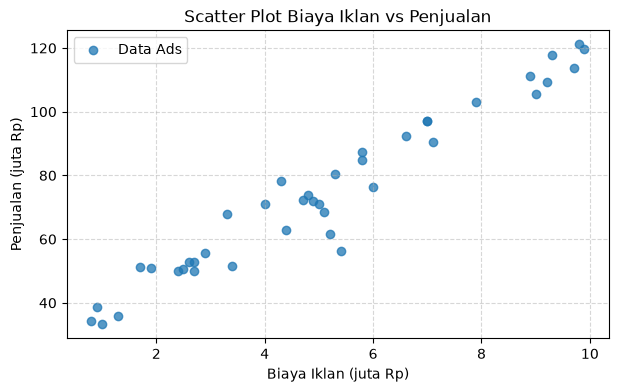

In [3]:
# A1. Load data, X dan y, scatter plot
ads_df = pd.read_csv(ADS_PATH)
print("Jumlah baris data:", len(ads_df))
display(ads_df.head())

X_ads = ads_df[["BiayaIklan"]].values   # 2 dimensi (n, 1)
y_ads = ads_df["Penjualan"].values      # 1 dimensi (n,)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

r = np.corrcoef(ads_df["BiayaIklan"], ads_df["Penjualan"])[0, 1]
print(f"Korelasi Pearson BiayaIklan vs Penjualan: {r:.4f}")

plt.figure(figsize=(7, 4))
plt.scatter(X_ads, y_ads, color="tab:blue", alpha=0.75, label="Data Ads")
plt.title("Scatter Plot Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

**Pengamatan A1:** titik-titik data membentuk pola naik hampir lurus (korelasi positif sangat kuat), sehingga model linear masuk akal dipakai.

### Soal A2 – Split Data

In [4]:
# A2. Split 80% training, 20% testing
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train_a.shape, "| X_test:", X_test_a.shape)
print("y_train:", y_train_a.shape, "| y_test:", y_test_a.shape)

X_train: (32, 1) | X_test: (8, 1)
y_train: (32,) | y_test: (8,)


### Soal A3 – Training dengan Normal Equation

In [5]:
# A3. Linear Regression - Normal Equation: theta = (X^T X)^-1 X^T y
class LinearRegression:
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]               # tambah kolom bias
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y        # pinv: lebih stabil dari inv
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


model_lr = LinearRegression().fit(X_train_a, y_train_a)
b_a, m_a = model_lr.intercept_, model_lr.coef_[0]
print(f"Intercept (b): {b_a:.4f}")
print(f"Koefisien (m): {m_a:.4f}")
print(f"Persamaan regresi: y_hat = {b_a:.4f} + {m_a:.4f} * X")

Intercept (b): 29.3864
Koefisien (m): 9.0711
Persamaan regresi: y_hat = 29.3864 + 9.0711 * X


**Jawaban A3 (interpretasi):**
Persamaan regresi: $\hat{y} = 29.3864 + 9.0711\,X$.

- **Koefisien $m = 9.0711$**: setiap kenaikan biaya iklan **1 juta Rp**, penjualan bulanan rata-rata naik sekitar **9,07 juta Rp** (dengan asumsi faktor lain tetap).
- **Intercept $b = 29.3864$**: perkiraan penjualan dasar (≈ 29,39 juta Rp) saat biaya iklan 0. Perlu hati-hati karena biaya iklan terkecil di data adalah 0,8 juta, jadi nilai ini hasil ekstrapolasi.

### Soal A4 – Evaluasi Model
MAE, MSE, RMSE, dan $R^2$ diimplementasikan manual dengan NumPy.

In [6]:
# A4. Metrik regresi manual
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot


y_tr_pred = model_lr.predict(X_train_a)
y_ts_pred = model_lr.predict(X_test_a)

df_eval_a = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R^2"],
    "Training": [f(y_train_a, y_tr_pred) for f in (mae, mse, rmse, r2_score)],
    "Testing": [f(y_test_a, y_ts_pred) for f in (mae, mse, rmse, r2_score)],
})
display(df_eval_a.round(4))

print(f"RMSE testing = {rmse(y_test_a, y_ts_pred) / y_ads.mean() * 100:.1f}% dari rata-rata penjualan "
      f"({y_ads.mean():.2f} juta Rp)")

,Metrik,Training,Testing
0,MAE,3.7920,7.2023
1,MSE,24.4404,87.1316
2,RMSE,4.9437,9.3344
3,R^2,0.9618,0.8464


RMSE testing = 12.6% dari rata-rata penjualan (74.27 juta Rp)


**Jawaban A4 (analisis):**

| Metrik | Training | Testing |
|---|---|---|
| MAE | 3.7921 | 7.2023 |
| MSE | 24.4404 | 87.1316 |
| RMSE | 4.9437 | 9.3344 |
| $R^2$ | 0.9618 | 0.8464 |

- **RMSE testing = 9,33** artinya rata-rata prediksi meleset sekitar **±9,3 juta Rp** dari penjualan sebenarnya (≈ 12,6% dari rata-rata penjualan 74,27 juta). RMSE memakai satuan yang sama dengan `y`, dan lebih sensitif terhadap kesalahan besar dibanding MAE.
- **$R^2$ testing = 0,846** artinya model menjelaskan sekitar **84,6%** variasi penjualan pada data baru; $R^2$ training 0,962.
- **Kesimpulan:** model sudah **cukup baik** karena $R^2$ tinggi di kedua set dan hubungan linear kuat. Namun error testing hampir dua kali error training (RMSE 9,33 vs 4,94). Selisih ini sebagian besar akibat data testing hanya **8 titik**, jadi metriknya sangat peka terhadap 1-2 titik yang sulit diprediksi. Ada indikasi *overfitting ringan*, tetapi belum parah karena $R^2$ testing masih tinggi.

### Soal A5 – Gradient Descent & Learning Rate

,Learning rate,Intercept,Koefisien,Selisih koef. vs Normal Eq.,MSE akhir,Status
0,0.001,26.2690,9.5481,0.4771,26.6019,konvergen
1,0.02,29.3864,9.0711,0.0000,24.4404,konvergen
2,0.1,NaN,NaN,NaN,NaN,DIVERGEN (iterasi ke-197)
3,Normal Eq.,29.3864,9.0711,0.0000,24.4404,solusi analitik


lambda_max Hessian = 68.86  ->  learning rate maksimum agar stabil ~ 0.0290


c:\Users\azka\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


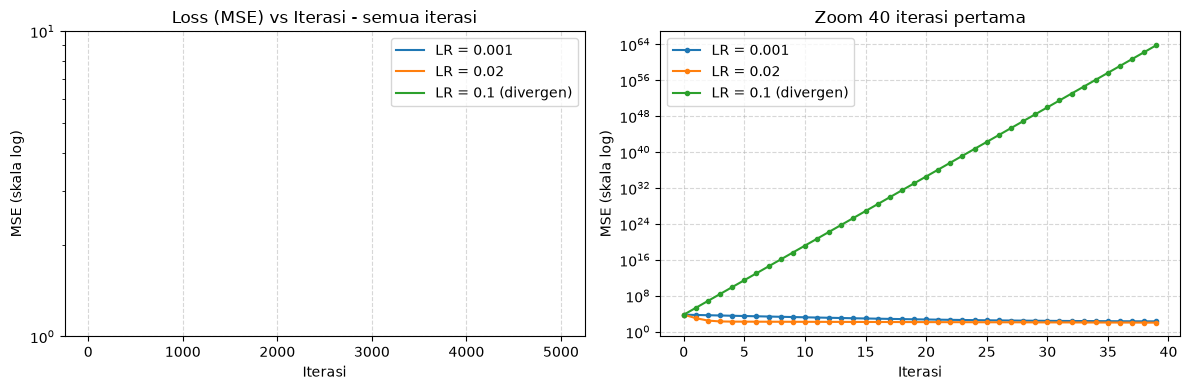

In [7]:
# A5. Gradient Descent untuk Linear Regression
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n = X.shape[0]
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history = []
        self.diverged_at = None
        with np.errstate(all="ignore"):   # overflow ditangani manual (lihat deteksi divergen di bawah)
            for i in range(self.n_iter):
                error = (self.intercept_ + X @ self.coef_) - y
                loss = np.mean(error ** 2)
                if not np.isfinite(loss):          # loss meledak -> divergen
                    self.diverged_at = i
                    break
                self.loss_history.append(loss)
                self.coef_ = self.coef_ - (2 / n) * self.lr * (X.T @ error)
                self.intercept_ = self.intercept_ - (2 / n) * self.lr * np.sum(error)
        return self


lr_list = [0.001, 0.02, 0.1]
gd_models, rows = {}, []
for lr in lr_list:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train_a, y_train_a)
    gd_models[lr] = gd
    ok = gd.diverged_at is None
    rows.append({
        "Learning rate": lr,
        "Intercept": gd.intercept_ if ok else np.nan,
        "Koefisien": gd.coef_[0] if ok else np.nan,
        "Selisih koef. vs Normal Eq.": abs(gd.coef_[0] - m_a) if ok else np.nan,
        "MSE akhir": gd.loss_history[-1] if ok else np.nan,
        "Status": "konvergen" if ok else f"DIVERGEN (iterasi ke-{gd.diverged_at})",
    })
rows.append({"Learning rate": "Normal Eq.", "Intercept": b_a, "Koefisien": m_a,
             "Selisih koef. vs Normal Eq.": 0.0, "MSE akhir": mse(y_train_a, model_lr.predict(X_train_a)),
             "Status": "solusi analitik"})
display(pd.DataFrame(rows).round(4))

# Batas learning rate stabil: lr < 2 / lambda_max(Hessian)
Xb = np.c_[np.ones(len(X_train_a)), X_train_a]
lam_max = np.linalg.eigvalsh((2 / len(X_train_a)) * Xb.T @ Xb).max()
print(f"lambda_max Hessian = {lam_max:.2f}  ->  learning rate maksimum agar stabil ~ {2 / lam_max:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lr, gd in gd_models.items():
    h = np.array(gd.loss_history)
    label = f"LR = {lr}" + ("" if gd.diverged_at is None else " (divergen)")
    ax[0].plot(h, label=label)
    ax[1].plot(h[:40], marker="o", ms=3, label=label)
ax[0].set_title("Loss (MSE) vs Iterasi - semua iterasi"); ax[0].set_yscale("log")
ax[1].set_title("Zoom 40 iterasi pertama"); ax[1].set_yscale("log")
for a in ax:
    a.set_xlabel("Iterasi"); a.set_ylabel("MSE (skala log)")
    a.grid(True, linestyle="--", alpha=0.5); a.legend()
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

- **LR = 0.001 → terlalu lambat.** Setelah 5000 iterasi hasilnya masih intercept 26.2690 dan koefisien 9.5481, belum sampai ke solusi normal equation (29.3864 dan 9.0711). Langkahnya terlalu kecil sehingga butuh iterasi jauh lebih banyak.
- **LR = 0.02 → pas.** Hasilnya identik dengan normal equation (intercept 29.3864, koefisien 9.0711); loss turun cepat lalu mendatar di nilai minimum.
- **LR = 0.1 → gagal konvergen (divergen).** Loss justru membesar tiap iterasi hingga meledak sampai `inf`/`nan`. Langkah update terlalu besar sehingga parameter "melompati" titik minimum dan melompat makin jauh di sisi seberang. Secara teori, GD untuk MSE stabil hanya jika $\text{LR} < 2/\lambda_{max}$ dari Hessian (batas dicetak di output di atas, nilainya jauh di bawah 0,1), sehingga 0,1 jelas di atas batas, sedangkan 0,02 masih di bawahnya.
- **`RuntimeWarning: overflow`** (pada versi sebelumnya) artinya angka melebihi batas representasi `float64` (~1e308). Itu bukti numerik bahwa training divergen, bukan bug program. Pada versi ini divergensi dideteksi dan dihentikan otomatis.

### Soal A6 – Visualisasi & Prediksi

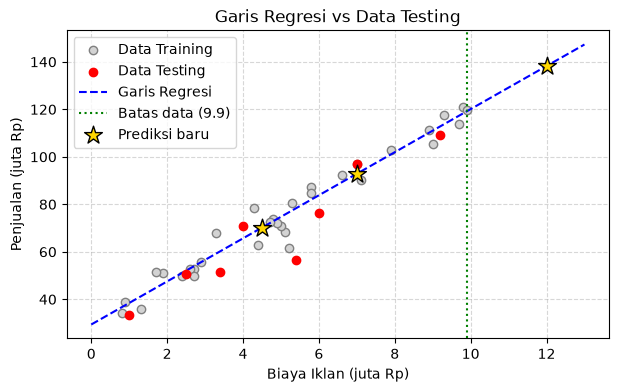

,Biaya Iklan (juta Rp),Prediksi Penjualan (juta Rp),Posisi
0,4.5,70.21,di dalam rentang data
1,7.0,92.88,di dalam rentang data
2,12.0,138.24,DI LUAR rentang (ekstrapolasi)


Rentang BiayaIklan pada data: 0.8 - 9.9 | Penjualan maksimum pada data: 121.1


In [8]:
# A6. Garis regresi vs data testing + prediksi
plt.figure(figsize=(7, 4))
plt.scatter(X_train_a, y_train_a, color="lightgray", edgecolor="gray", label="Data Training", zorder=2)
plt.scatter(X_test_a, y_test_a, color="red", label="Data Testing", zorder=3)
x_line = np.linspace(0, 13, 100).reshape(-1, 1)
plt.plot(x_line, model_lr.predict(x_line), "b--", label="Garis Regresi")
plt.axvline(X_ads.max(), color="green", linestyle=":", label=f"Batas data ({X_ads.max():.1f})")

X_new = np.array([[4.5], [7.0], [12.0]])
preds = model_lr.predict(X_new)
plt.scatter(X_new, preds, marker="*", s=180, color="gold", edgecolor="black", label="Prediksi baru", zorder=4)
plt.title("Garis Regresi vs Data Testing")
plt.xlabel("Biaya Iklan (juta Rp)"); plt.ylabel("Penjualan (juta Rp)")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.show()

lo, hi = X_ads.min(), X_ads.max()
df_pred = pd.DataFrame({
    "Biaya Iklan (juta Rp)": X_new.ravel(),
    "Prediksi Penjualan (juta Rp)": preds.round(2),
    "Posisi": ["di dalam rentang data" if lo <= v <= hi else "DI LUAR rentang (ekstrapolasi)" for v in X_new.ravel()],
})
display(df_pred)
print(f"Rentang BiayaIklan pada data: {lo} - {hi} | Penjualan maksimum pada data: {y_ads.max()}")

**Jawaban A6 (analisis):**

| Biaya iklan | Prediksi penjualan |
|---|---|
| 4,5 juta | 70,21 juta |
| 7,0 juta | 92,88 juta |
| 12,0 juta | 138,24 juta |

Prediksi untuk 4,5 dan 7 juta berada **di dalam rentang data** (0,8-9,9 juta), sehingga cukup bisa dipercaya (galat khas sekitar ±9 juta, sesuai RMSE testing).

Prediksi untuk **12 juta merupakan ekstrapolasi** (di luar data maksimum 9,9 juta) dan hasilnya 138,24 juta, lebih tinggi dari penjualan terbesar yang pernah diamati (121,1 juta). Hasil ini **kurang bisa dipercaya** karena model hanya belajar dari rentang 0,8-9,9 juta dan mengasumsikan hubungan tetap lurus selamanya. Pada praktiknya, iklan biasanya mengalami *diminishing returns* (kenaikan penjualan makin kecil di biaya tinggi) atau pasar bisa jenuh, sehingga penjualan sebenarnya kemungkinan lebih rendah dari 138 juta. Untuk keputusan di biaya 12 juta sebaiknya dikumpulkan data baru di rentang tersebut.

---
# Bagian B – Logistic Regression (40%)
Filter **spam** berdasarkan jumlah link dan jumlah kata promosi (`Email_Data.csv`).

### Soal B1 – Load & Visualisasi Data

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah data: 60
Bukan Spam (0): 35 email | Spam (1): 25 email
Jumlah baris duplikat: 6 (dibiarkan, karena nilai kembar wajar pada data hitungan bilangan bulat)


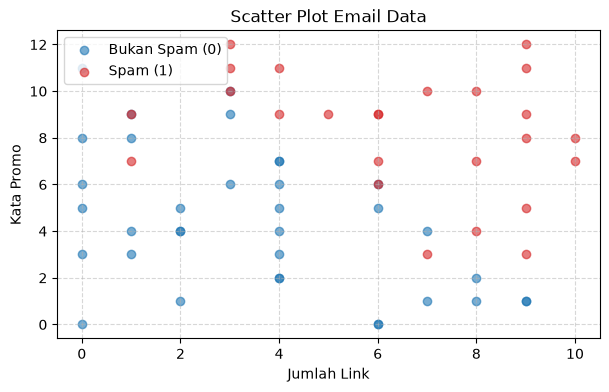

In [9]:
# B1. Load data, hitung kelas, scatter plot
email_df = pd.read_csv(EMAIL_PATH)
display(email_df.head())
print("Jumlah data:", len(email_df))
counts = email_df["Spam"].value_counts().sort_index()
print(f"Bukan Spam (0): {counts[0]} email | Spam (1): {counts[1]} email")
print("Jumlah baris duplikat:", int(email_df.duplicated().sum()),
      "(dibiarkan, karena nilai kembar wajar pada data hitungan bilangan bulat)")

X_email = email_df[["JumlahLink", "KataPromo"]].values
y_email = email_df["Spam"].values

plt.figure(figsize=(7, 4))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color="tab:blue", alpha=0.6, label="Bukan Spam (0)")
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color="tab:red", alpha=0.6, label="Spam (1)")
plt.title("Scatter Plot Email Data")
plt.xlabel("Jumlah Link"); plt.ylabel("Kata Promo")
plt.grid(True, linestyle="--", alpha=0.5); plt.legend()
plt.show()

**Pengamatan B1:** terdapat 25 email spam (41,7%) dan 35 bukan spam. Email spam cenderung berada di kanan-atas (banyak link dan banyak kata promo), sedangkan bukan spam di kiri-bawah. Kedua kelas relatif terpisah, tetapi ada daerah tumpang tindih di tengah. Ada 6 baris duplikat; karena duplikat bisa jatuh di training dan testing sekaligus, akurasi testing bisa sedikit optimistis.

### Soal B2 – Split Data & Training

X_train: (45, 2) | X_test: (15, 2)
Intercept (b): -11.1911 | m1 (JumlahLink): 1.0264 | m2 (KataPromo): 0.8778
P(Spam) = sigmoid(-11.1911 + 1.0264*JumlahLink + 0.8778*KataPromo)
Log loss awal: 0.6931 | akhir: 0.2638 | penurunan 1000 iterasi terakhir: 0.000635


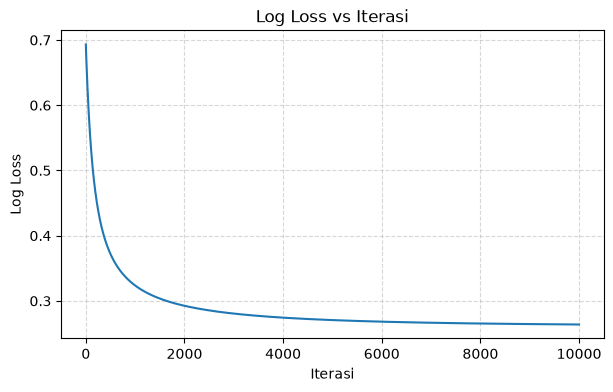

In [10]:
# B2. Split 75/25 dan training Logistic Regression (gradient descent)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train_b.shape, "| X_test:", X_test_b.shape)


class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))   # clip agar tidak overflow

    def fit(self, X, y):
        n, d = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(d)
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iter):
            p = self._sigmoid(self.intercept_ + X @ self.coef_)
            self.coef_ -= self.lr * (X.T @ (p - y)) / n
            self.intercept_ -= self.lr * np.sum(p - y) / n
            p_c = np.clip(p, eps, 1 - eps)
            self.loss_history.append(-np.mean(y * np.log(p_c) + (1 - y) * np.log(1 - p_c)))
        return self

    def predict_proba(self, X):
        return self._sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


model_log = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_b, y_train_b)
b_b = model_log.intercept_
m1_b, m2_b = model_log.coef_
print(f"Intercept (b): {b_b:.4f} | m1 (JumlahLink): {m1_b:.4f} | m2 (KataPromo): {m2_b:.4f}")
print(f"P(Spam) = sigmoid({b_b:.4f} + {m1_b:.4f}*JumlahLink + {m2_b:.4f}*KataPromo)")

h = np.array(model_log.loss_history)
print(f"Log loss awal: {h[0]:.4f} | akhir: {h[-1]:.4f} | penurunan 1000 iterasi terakhir: {h[-1000] - h[-1]:.6f}")

plt.figure(figsize=(7, 4))
plt.plot(h)
plt.title("Log Loss vs Iterasi"); plt.xlabel("Iterasi"); plt.ylabel("Log Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Jawaban B2 (analisis):**
Persamaan model: $P(\text{Spam}) = \sigma(-11.1911 + 1.0264\cdot\text{JumlahLink} + 0.8778\cdot\text{KataPromo})$.

Kedua koefisien **positif**, artinya semakin banyak link dan semakin banyak kata promo, probabilitas spam naik (setiap tambahan 1 link menaikkan *log-odds* sebesar 1,03; tiap tambahan 1 kata promo sebesar 0,88).

Grafik log loss **turun tajam di awal lalu melandai dan stabil** mendekati akhir iterasi (penurunan pada 1000 iterasi terakhir sangat kecil, lihat angka di output), jadi training sudah konvergen dan 10.000 iterasi sudah memadai.

### Soal B3 – Evaluasi Model

In [11]:
# B3. Metrik klasifikasi manual
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0)); fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0)); tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred); tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred); tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0


def report(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1-score": f1_score(y_true, y_pred)}


y_pred_tr = model_log.predict(X_train_b)
y_pred_ts = model_log.predict(X_test_b)
display(pd.DataFrame({"Training": report(y_train_b, y_pred_tr), "Testing": report(y_test_b, y_pred_ts)}).round(4))

cm_ts = confusion_matrix(y_test_b, y_pred_ts)
print("Confusion matrix (testing):  baris = aktual, kolom = prediksi")
display(pd.DataFrame(cm_ts, index=["Aktual Bukan Spam", "Aktual Spam"], columns=["Pred Bukan Spam", "Pred Spam"]))
print(f"TN={cm_ts[0,0]}  FP={cm_ts[0,1]}  FN={cm_ts[1,0]}  TP={cm_ts[1,1]}")

,Training,Testing
Accuracy,0.9111,0.9333
Precision,0.8667,1.0000
Recall,0.8667,0.9000
F1-score,0.8667,0.9474


Confusion matrix (testing):  baris = aktual, kolom = prediksi


,Pred Bukan Spam,Pred Spam
Aktual Bukan Spam,5,0
Aktual Spam,1,9


TN=5  FP=0  FN=1  TP=9


**Jawaban B3 (analisis):**
Pada data testing (15 email): accuracy 0,9333; precision 1,0000; recall 0,9000; F1 0,9474; confusion matrix TN=5, FP=0, FN=1, TP=9.

- **FP (false positive):** email **normal** yang salah ditandai **spam** (bisa masuk folder spam/terhapus).
- **FN (false negative):** email **spam** yang lolos ke **inbox**.
- **Kesalahan yang lebih merugikan: FP.** Email penting (tagihan, lamaran kerja, info akademik) yang hilang bisa berakibat fatal dan pengguna tidak sadar karena email tidak pernah terlihat. FN hanya mengganggu karena pengguna masih bisa menghapus spam secara manual. Model ini kebetulan FP = 0 (precision 1,0) dan hanya 1 spam yang lolos (recall 0,9).

### Soal B4 – Decision Boundary

Decision boundary: x2 = -(-11.1911 + 1.0264 * x1) / 0.8778
                   x2 = 12.7491 + (-1.1693) * x1


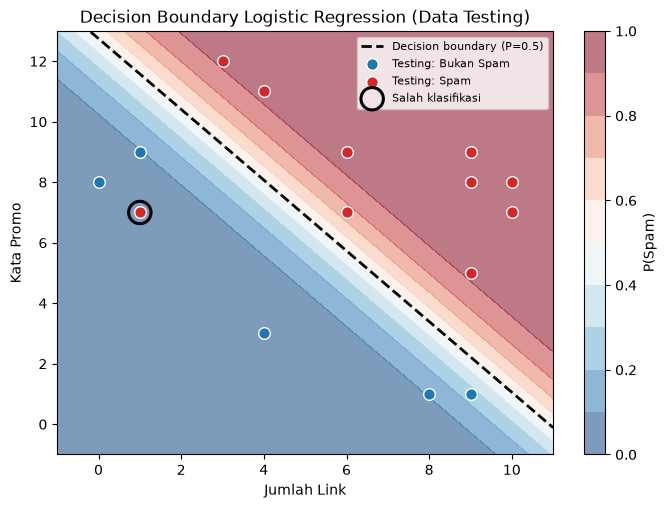

Jumlah data testing salah klasifikasi: 1 dari 15


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,1,7,1,0,0.0176


In [12]:
# B4. Decision boundary: b + m1*x1 + m2*x2 = 0  ->  x2 = -(b + m1*x1)/m2
print(f"Decision boundary: x2 = -({b_b:.4f} + {m1_b:.4f} * x1) / {m2_b:.4f}")
print(f"                   x2 = {-b_b / m2_b:.4f} + ({-m1_b / m2_b:.4f}) * x1")

x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
probs = model_log.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

wrong = y_pred_ts != y_test_b
fig, ax = plt.subplots(figsize=(8, 5.5))
cf = ax.contourf(xx1, xx2, probs, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.55)
plt.colorbar(cf, label="P(Spam)")
x1_line = np.linspace(x1_min, x1_max, 100)
ax.plot(x1_line, -(b_b + m1_b * x1_line) / m2_b, "k--", lw=2, label="Decision boundary (P=0.5)")
for cls, col, name in [(0, "tab:blue", "Testing: Bukan Spam"), (1, "tab:red", "Testing: Spam")]:
    m = (y_test_b == cls)
    ax.scatter(X_test_b[m, 0], X_test_b[m, 1], c=col, edgecolor="white", s=70, label=name, zorder=3)
ax.scatter(X_test_b[wrong, 0], X_test_b[wrong, 1], facecolors="none", edgecolors="black",
           s=260, linewidths=2.2, label="Salah klasifikasi", zorder=4)
ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
ax.set_title("Decision Boundary Logistic Regression (Data Testing)")
ax.set_xlabel("Jumlah Link"); ax.set_ylabel("Kata Promo"); ax.legend(loc="upper right", fontsize=8)
plt.show()

df_wrong = pd.DataFrame({
    "JumlahLink": X_test_b[wrong, 0], "KataPromo": X_test_b[wrong, 1],
    "Aktual": y_test_b[wrong], "Prediksi": y_pred_ts[wrong],
    "P(Spam)": model_log.predict_proba(X_test_b[wrong]).round(4),
})
print(f"Jumlah data testing salah klasifikasi: {wrong.sum()} dari {len(y_test_b)}")
display(df_wrong)

**Jawaban B4 (analisis):**
Decision boundary berupa **garis lurus** karena Logistic Regression memakai kombinasi linear fitur. Daerah di atas/kanan garis diprediksi spam (merah), di bawah/kiri bukan spam (biru); warna makin pekat berarti model makin yakin.

Terdapat **1 data testing yang salah diklasifikasikan** (ditandai lingkaran hitam, detail ada di tabel output). Sesuai confusion matrix (FN=1, FP=0), kesalahan itu adalah **email spam yang diprediksi bukan spam**: titiknya berada di sisi "bukan spam" dari garis (nilai P(Spam)-nya ada di tabel output; semakin dekat ke 0,5 berarti semakin tipis selisihnya). Titik seperti ini umumnya berada di daerah tumpang tindih kedua kelas yang tidak bisa dipisah sempurna oleh satu garis lurus.

### Soal B5 – Eksperimen Threshold

In [13]:
# B5. Eksperimen threshold
proba_ts = model_log.predict_proba(X_test_b)

def threshold_table(thresholds):
    rows = []
    for th in thresholds:
        pred = (proba_ts >= th).astype(int)
        cm = confusion_matrix(y_test_b, pred)
        rows.append({"Threshold": th, "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
                     "Precision": precision_score(y_test_b, pred), "Recall": recall_score(y_test_b, pred),
                     "F1-score": f1_score(y_test_b, pred), "Accuracy": accuracy_score(y_test_b, pred)})
    return pd.DataFrame(rows).round(4)

print("Threshold yang diminta soal:")
display(threshold_table([0.3, 0.5, 0.7]))
print("Sapuan threshold lebih lebar (untuk melihat kapan hasil mulai berubah):")
display(threshold_table([0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]))

Threshold yang diminta soal:


,Threshold,TN,FP,FN,TP,Precision,Recall,F1-score,Accuracy
0,0.3,5,0,1,9,1.0,0.9,0.9474,0.9333
1,0.5,5,0,1,9,1.0,0.9,0.9474,0.9333
2,0.7,5,0,1,9,1.0,0.9,0.9474,0.9333


Sapuan threshold lebih lebar (untuk melihat kapan hasil mulai berubah):


,Threshold,TN,FP,FN,TP,Precision,Recall,F1-score,Accuracy
0,0.05,2,3,1,9,0.7500,0.9,0.8182,0.7333
1,0.10,3,2,1,9,0.8182,0.9,0.8571,0.8000
2,0.20,4,1,1,9,0.9000,0.9,0.9000,0.8667
3,0.30,5,0,1,9,1.0000,0.9,0.9474,0.9333
4,0.50,5,0,1,9,1.0000,0.9,0.9474,0.9333
5,0.70,5,0,1,9,1.0000,0.9,0.9474,0.9333
6,0.80,5,0,2,8,1.0000,0.8,0.8889,0.8667
7,0.90,5,0,2,8,1.0000,0.8,0.8889,0.8667
8,0.95,5,0,6,4,1.0000,0.4,0.5714,0.6000
9,0.99,5,0,6,4,1.0000,0.4,0.5714,0.6000


**Jawaban B5 (analisis):**
Pada threshold 0,3 / 0,5 / 0,7 hasilnya **sama persis** (TN=5, FP=0, FN=1, TP=9; precision 1,0; recall 0,9). Alasannya: data testing hanya 15 email dan model sangat yakin pada kebanyakan email (probabilitasnya mendekati 0 atau 1), sehingga hampir tidak ada email testing yang probabilitasnya berada di antara 0,3 dan 0,7. Efek threshold baru terlihat jika dicoba nilai yang lebih ekstrem (lihat tabel sapuan kedua di output).

**Pengaruh threshold secara umum:**
- **Threshold dinaikkan** → model lebih "pelit" melabeli spam → **precision naik** (FP turun), tetapi **recall turun** (lebih banyak spam lolos).
- **Threshold diturunkan** → model lebih "agresif" → **recall naik** (spam tertangkap), tetapi **precision turun** (lebih banyak email normal salah diblokir).

**Threshold pilihan: 0,7.** Dari Soal B3, kesalahan yang paling merugikan adalah FP (email penting terblokir). Pada data testing, 0,7 tidak mengorbankan recall dibanding 0,5 dan lebih melindungi dari FP pada email baru yang "abu-abu". Sebagai catatan, karena data testing kecil, pilihan ini lebih didasarkan pada pertimbangan biaya kesalahan daripada perbedaan angka metrik.

### Soal B6 – Prediksi Email Baru

In [14]:
# B6. Prediksi email baru dengan threshold pilihan (0.7)
THRESHOLD_PILIHAN = 0.7
new_emails = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])
proba_new = model_log.predict_proba(new_emails)
df_new = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": new_emails[:, 0], "KataPromo": new_emails[:, 1],
    "P(Spam)": proba_new.round(4),
    f"Prediksi (th={THRESHOLD_PILIHAN})": np.where(proba_new >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam"),
    "Prediksi (th=0.5)": np.where(proba_new >= 0.5, "Spam", "Bukan Spam"),
})
display(df_new)

,Email,JumlahLink,KataPromo,P(Spam),Prediksi (th=0.7),Prediksi (th=0.5)
0,E1,1,2,0.0002,Bukan Spam,Bukan Spam
1,E2,5,6,0.3117,Bukan Spam,Bukan Spam
2,E3,9,10,0.9989,Spam,Spam
3,E4,2,11,0.6266,Bukan Spam,Spam


**Pembahasan B6:** E1 (P=0,0002) jelas bukan spam dan E3 (P=0,9989) jelas spam. E2 (P=0,3117) bukan spam pada threshold 0,5 maupun 0,7. **E4 (P=0,6266) adalah kasus abu-abu**: dengan threshold 0,5 ia spam, tetapi dengan threshold pilihan 0,7 ia dianggap bukan spam, sehingga masuk inbox (prioritas menghindari FP). Jika pengguna lebih ingin bersih dari spam, threshold 0,5 bisa dipakai.

---
# Bagian C – Pemahaman Konsep (15%)

**Jawaban C1 – Logistic Regression & sigmoid:**
Logistic Regression memakai nama "regression" karena langkah awalnya sama seperti regresi linear, yaitu menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$. Namun tujuannya adalah **memprediksi kelas (kategori)**, bukan angka kontinu, sehingga ia termasuk algoritma klasifikasi. Fungsi **sigmoid** $\sigma(z) = 1/(1+e^{-z})$ mengubah $z$ (yang bisa bernilai berapa pun) menjadi angka 0-1 yang dibaca sebagai probabilitas kelas positif. Probabilitas ini kemudian dibandingkan dengan threshold (default 0,5) untuk menentukan kelas akhir, misalnya spam atau bukan spam.

**Jawaban C2 – Normal equation vs gradient descent:**
Normal equation menghitung parameter langsung (sekali hitung) dengan rumus matriks $\theta = (X^TX)^{-1}X^Ty$, tanpa learning rate dan tanpa iterasi. Gradient descent mencari parameter secara bertahap: menghitung gradien loss lalu menggeser parameter sedikit demi sedikit ke arah penurunan loss, dan hasilnya bergantung pada learning rate serta jumlah iterasi. Normal equation bagus untuk data kecil dengan fitur sedikit (seperti dataset ini), tetapi menghitung invers matriks berbiaya sekitar $O(d^3)$ sehingga lambat bila fitur sangat banyak. Gradient descent lebih cocok untuk **data/fitur berukuran sangat besar**, bisa dipakai untuk model tanpa solusi tertutup (misalnya Logistic Regression dan neural network), dan dapat diproses per batch.

**Jawaban C3 – Data testing & overfitting:**
Model dievaluasi pada data testing karena tujuan utamanya adalah bekerja baik pada **data baru yang belum pernah dilihat**. Skor pada data training bisa menipu karena model sudah "melihat" jawabannya. **Overfitting** terjadi ketika model terlalu menyesuaikan diri dengan detail dan noise pada data training sehingga skor training sangat bagus tetapi skor testing jauh lebih buruk. Pada tugas ini, $R^2$ training 0,9618 vs testing 0,8464 dan RMSE 4,94 vs 9,33 menunjukkan gejala overfitting ringan (selisih juga dipengaruhi jumlah data testing yang hanya 8).

**Jawaban C4 – MSE vs log loss:**
Linear Regression menghasilkan output **kontinu** sehingga wajar diukur dengan selisih kuadrat (MSE) antara nilai prediksi dan nilai aktual. Logistic Regression menghasilkan **probabilitas** untuk label biner (0/1), sehingga loss yang tepat adalah log loss (*binary cross-entropy*) yang menghukum sangat berat jika model yakin tetapi salah (misal memprediksi P=0,99 padahal kelas aslinya 0). Jika MSE dipakai dengan sigmoid, fungsi loss menjadi non-konveks (banyak minimum lokal, gradien mengecil saat sigmoid jenuh) sehingga training lebih sulit. Log loss bersifat konveks pada Logistic Regression dan berasal dari prinsip *maximum likelihood*.

**Jawaban C5 – Mengapa hasil bisa berbeda antar mahasiswa:**
Karena `random_state` tiap mahasiswa berbeda (2 digit terakhir NIM), pengacakan data pada `train_test_split` juga berbeda. Akibatnya data yang masuk ke training dan testing berbeda, sehingga koefisien, intercept, dan metrik evaluasi (R², akurasi, dll) ikut berbeda walaupun dataset dan algoritmanya sama. Pada dataset kecil seperti ini (40 dan 60 baris), perbedaan itu cukup terasa karena satu data saja bisa mengubah hasil. Ini juga alasan mengapa hasil dari satu kali split sebaiknya tidak dianggap pasti, melainkan dilihat bersama konsep seperti cross-validation.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

In [15]:
# Bonus: bandingkan dengan scikit-learn (hanya dipakai di sel ini)
import warnings
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import accuracy_score as sk_acc, f1_score as sk_f1, r2_score as sk_r2

# --- Linear Regression ---
sk_lr = SkLinearRegression().fit(X_train_a, y_train_a)
print("== Linear Regression ==")
display(pd.DataFrame({
    "Manual (Normal Eq.)": [b_a, m_a, r2_score(y_test_a, model_lr.predict(X_test_a))],
    "scikit-learn": [sk_lr.intercept_, sk_lr.coef_[0], sk_r2(y_test_a, sk_lr.predict(X_test_a))],
}, index=["Intercept", "Koefisien", "R^2 testing"]).round(6))

# --- Logistic Regression ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sk_log_default = SkLogisticRegression(C=1.0, max_iter=10000).fit(X_train_b, y_train_b)    # default: L2, C=1
    sk_log_noreg = SkLogisticRegression(C=1e10, max_iter=100000).fit(X_train_b, y_train_b)    # ~ tanpa regularisasi

def row(coef0, coef, pred):
    return [coef0, coef[0], coef[1], accuracy_score(y_test_b, pred), f1_score(y_test_b, pred)]

df_cmp = pd.DataFrame({
    "Manual (GD, tanpa reg.)": row(model_log.intercept_, model_log.coef_, model_log.predict(X_test_b)),
    "sklearn default (L2, C=1)": row(sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(X_test_b)),
    "sklearn C=1e10 (~tanpa reg.)": row(sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(X_test_b)),
}, index=["Intercept", "Koef JumlahLink", "Koef KataPromo", "Accuracy testing", "F1 testing"])
print("\n== Logistic Regression ==")
display(df_cmp.round(4))

== Linear Regression ==


,Manual (Normal Eq.),scikit-learn
Intercept,29.386389,29.386389
Koefisien,9.071079,9.071079
R^2 testing,0.846418,0.846418



== Logistic Regression ==


,"Manual (GD, tanpa reg.)","sklearn default (L2, C=1)",sklearn C=1e10 (~tanpa reg.)
Intercept,-11.1911,-10.4979,-13.2276
Koef JumlahLink,1.0264,0.9537,1.2214
Koef KataPromo,0.8778,0.8242,1.0340
Accuracy testing,0.9333,0.9333,0.9333
F1 testing,0.9474,0.9474,0.9474


**Jawaban Bonus (analisis):**

- **Linear Regression:** hasil scikit-learn dan implementasi manual **identik** (intercept 29.3864; koefisien 9.0711), karena keduanya menyelesaikan masalah *least squares* yang sama dengan solusi tertutup.
- **Logistic Regression:** pada pengaturan default, koefisien scikit-learn (intercept -10.4979; koefisien 0.9537 dan 0.8242) **lebih kecil** daripada implementasi manual (intercept -11.1911; koefisien 1.0264 dan 0.8778). Penyebabnya: `LogisticRegression` scikit-learn secara default memakai **regularisasi L2 dengan `C=1.0`** (`penalty='l2'`) yang menambah penalti terhadap besarnya koefisien sehingga bobot "disusutkan" mendekati nol. Implementasi manual kita **tanpa regularisasi**. Ketika `C` dibuat sangat besar (regularisasi dihilangkan, kolom ketiga tabel), koefisien scikit-learn **naik dan tidak lagi menyusut**, sehingga setara atau bahkan lebih besar daripada hasil manual. Ini wajar: pada data yang hampir terpisah sempurna, solusi optimum tanpa regularisasi memiliki koefisien besar, sedangkan gradient descent manual berhenti setelah 10.000 iterasi (belum konvergen sepenuhnya), dan scikit-learn memakai solver `lbfgs` yang berbeda. Meski koefisien berbeda, akurasi dan F1 pada data testing tetap sangat mirip (lihat tabel) karena garis keputusan hanya bergeser/diskalakan; regularisasi terutama mengubah *keyakinan* probabilitas dan ketahanan terhadap overfitting.